# 06f · Wider LightGBM search with Optuna and early stopping

06b tuned LightGBM with 20 random configurations and searched `n_estimators` directly. This notebook tests whether a better tuning procedure finds a better model:

- **Optuna** (TPE sampler, seed 4012) over a wider space that adds `max_depth`, `reg_alpha` and `min_split_gain`, with a **median pruner** that stops weak trials after their first folds.
- **Early stopping** instead of searching the tree count: inside every training fold, an inner 20% stratified split picks the number of trees (up to 3,000, patience 100, monitored on average precision). The model is then refitted on the whole training fold with that many trees.

**Protocol**
- Leak-free training table from 06e and the shared folds. **The test file is never opened**; the held-out set has been used once, so nothing here can replace the frozen model's evaluation.
- Original class balance only: SMOTE lost in every model family in 06b/06c, and class weighting tied with original.
- Searching harder on the same 5 folds flatters the winner. So the comparison that counts is **nested CV** (Section 4): for each of the 5 shared folds, the *whole* tuning procedure runs on the other four, with 3 inner folds, and the fold it never saw scores the result. The old 06b procedure is nested the same way, so the two procedures are compared like for like.
- Section 5 rescores the search winner and the frozen configuration on new fold splits (3 × repeated 5-fold) as a second check.

| Section | What it does |
|---|---|
| 1–2 | Setup and the early-stopping CV routine |
| 3 | Optuna search on the shared folds |
| 4 | Nested CV: new procedure vs 06b procedure |
| 5 | Repeated-CV head-to-head: search winner vs frozen configuration |
| 6 | Operating point and development-only refit |

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import joblib
import lightgbm
import numpy as np
import optuna
import pandas as pd
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import ParameterSampler, RepeatedStratifiedKFold, StratifiedKFold, train_test_split

pd.set_option("display.float_format", "{:.4f}".format)
optuna.logging.set_verbosity(optuna.logging.WARNING)

QUICK_RUN = os.environ.get("QUICK_RUN") == "1"   # smoke test only
SEED, N_FOLDS, N_JOBS = 4012, 5, 4
N_TRIALS = 6 if QUICK_RUN else 150            # Section 3
N_TRIALS_NESTED = 4 if QUICK_RUN else 40      # per outer fold, Section 4
N_INNER = 3
N_REPEATS = 1 if QUICK_RUN else 3             # Section 5
MAX_TREES, ES_ROUNDS, ES_FRACTION = 3000, 100, 0.2

ROOT = Path("..")
TRAIN_PATH = ROOT / "data/processed/provider_features_train_leakfree.csv"
FROZEN_RUN = ROOT / "artifacts/boosting/20261011_232303_full"
RUN_ID = time.strftime("%Y%m%d_%H%M%S") + ("_quick" if QUICK_RUN else "_full") + "_leakfree"
RUN_DIR = ROOT / "artifacts/tuning" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

ID, TARGET = "Provider", "PotentialFraud"
frozen_meta = json.loads((FROZEN_RUN / "selected_metadata.json").read_text())
features = frozen_meta["feature_order"]
FROZEN_PARAMS = frozen_meta["params"]

train = pd.read_csv(TRAIN_PATH)
folds_df = pd.read_csv(ROOT / "artifacts/shared/cv_folds.csv")
assert train[ID].tolist() == folds_df[ID].tolist(), "Training table order differs from the shared folds"
assert (train[TARGET].to_numpy() == folds_df[TARGET].to_numpy()).all()
X, y, folds = train[features], train[TARGET].to_numpy(), folds_df["fold"].to_numpy()
print(f"{len(y)} training providers ({int(y.sum())} positive), {N_FOLDS} shared folds; "
      f"{N_TRIALS} trials; outputs -> {RUN_DIR}")

4328 training providers (405 positive), 5 shared folds; 150 trials; outputs -> ../artifacts/tuning/20261115_143207_full_leakfree


## 1–2. Early-stopping CV

`fit_early_stopped` fits the imputer on the inner-training rows only, so the early-stopping rows stay unseen. It then refits imputer + model on the full training fold with the chosen tree count. `fixed_pipeline` is 06b's pipeline (median imputation → LightGBM with a fixed tree count).

In [2]:
BASE = {"objective": "binary", "random_state": SEED, "n_jobs": N_JOBS, "verbose": -1}


def fixed_pipeline(params):
    return ImbPipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True).set_output(transform="pandas")),
        ("model", LGBMClassifier(**BASE, **params))])


def fit_early_stopped(X_tr, y_tr, params, seed):
    i_fit, i_es = train_test_split(np.arange(len(y_tr)), test_size=ES_FRACTION, stratify=y_tr, random_state=seed)
    imp = SimpleImputer(strategy="median", keep_empty_features=True).set_output(transform="pandas")
    imp.fit(X_tr.iloc[i_fit])
    probe = LGBMClassifier(**BASE, **params, n_estimators=MAX_TREES, metric="average_precision")
    probe.fit(imp.transform(X_tr.iloc[i_fit]), y_tr[i_fit],
              eval_set=[(imp.transform(X_tr.iloc[i_es]), y_tr[i_es])],
              callbacks=[lightgbm.early_stopping(ES_ROUNDS, verbose=False)])
    n_trees = max(int(probe.best_iteration_), 1)
    return fixed_pipeline({**params, "n_estimators": n_trees}).fit(X_tr, y_tr), n_trees


def cv_early_stopped(params, X_, y_, fold_ids, trial=None):
    """Mean fold AP with early stopping per fold; reports the running mean to Optuna for pruning."""
    oof, aps, trees = np.full(len(y_), np.nan), [], []
    for step, k in enumerate(np.unique(fold_ids)):
        tr, va = np.where(fold_ids != k)[0], np.where(fold_ids == k)[0]
        model, n = fit_early_stopped(X_.iloc[tr], y_[tr], params, seed=SEED + int(k))
        oof[va] = model.predict_proba(X_.iloc[va])[:, 1]
        aps.append(average_precision_score(y_[va], oof[va]))
        trees.append(n)
        if trial is not None:
            trial.report(float(np.mean(aps)), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return np.array(aps), trees, oof


def cv_fixed(params, X_, y_, fold_ids):
    oof, aps = np.full(len(y_), np.nan), []
    for k in np.unique(fold_ids):
        tr, va = np.where(fold_ids != k)[0], np.where(fold_ids == k)[0]
        oof[va] = fixed_pipeline(params).fit(X_.iloc[tr], y_[tr]).predict_proba(X_.iloc[va])[:, 1]
        aps.append(average_precision_score(y_[va], oof[va]))
    return np.array(aps), oof


def suggest(trial):
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
        "max_depth": trial.suggest_categorical("max_depth", [-1, 3, 4, 5, 6, 8, 10]),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 1.0),
    }


def run_search(X_, y_, fold_ids, n_trials, seed):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1))

    def objective(trial):
        params = suggest(trial)
        aps, trees, _ = cv_early_stopped(params, X_, y_, fold_ids, trial)
        trial.set_user_attr("ap_std", float(aps.std(ddof=1)))
        trial.set_user_attr("median_trees", float(np.median(trees)))
        return float(aps.mean())

    study.optimize(objective, n_trials=n_trials)
    return study, {**study.best_params, "subsample_freq": 1}


# 06b's procedure: 20 random configurations with a fixed tree count, from 06b's space and sampler seed
LGBM_SPACE_06B = {
    "n_estimators": randint(200, 800), "learning_rate": loguniform(0.01, 0.2), "num_leaves": randint(8, 64),
    "min_child_samples": randint(10, 60), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
    "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-2, 10),
}
CONFIGS_06B = [{k: (v.item() if hasattr(v, "item") else v) for k, v in c.items()}
               for c in ParameterSampler(LGBM_SPACE_06B, n_iter=20, random_state=SEED)]
assert CONFIGS_06B[frozen_meta["config_id"]] == FROZEN_PARAMS

## 3. Optuna search on the shared folds

The best trial's mean fold AP is **optimistic**: it is the maximum over many trials scored on the same folds. Use it to pick a configuration, and Sections 4–5 to judge it. For reference, the frozen configuration and 06b's best on this same leak-free table are rescored here too.

In [3]:
t0 = time.time()
study, best_params = run_search(X, y, folds, N_TRIALS, SEED)
trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
trials.to_csv(RUN_DIR / "optuna_trials.csv", index=False)

best_aps, best_trees, best_oof = cv_early_stopped(best_params, X, y, folds)
frozen_aps, frozen_oof = cv_fixed(FROZEN_PARAMS, X, y, folds)
n_done = int((trials["state"] == "COMPLETE").sum())
print(f"{len(trials)} trials ({n_done} completed, {len(trials) - n_done} pruned) in {time.time() - t0:.0f}s")
print("Best parameters:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})
print("Trees chosen per fold:", best_trees)

shared_fold_table = pd.DataFrame({
    "Optuna best (early stopping)": best_aps,
    "Frozen 06b configuration": frozen_aps,
}, index=pd.Index(range(N_FOLDS), name="fold"))
shared_fold_table.loc["mean"] = shared_fold_table.mean()
shared_fold_table.loc["SD"] = shared_fold_table.iloc[:N_FOLDS].std(ddof=1)
shared_fold_table

150 trials (81 completed, 69 pruned) in 291s
Best parameters: {'learning_rate': 0.0392, 'num_leaves': 85, 'max_depth': 3, 'min_child_samples': 7, 'subsample': 0.837, 'colsample_bytree': 0.7132, 'reg_lambda': 0.0015, 'reg_alpha': 0.0061, 'min_split_gain': 0.8089, 'subsample_freq': 1}
Trees chosen per fold: [179, 126, 148, 98, 291]


,Optuna best (early stopping),Frozen 06b configuration
fold,,
0,0.6848,0.6861
1,0.6671,0.6541
2,0.6967,0.6777
3,0.6510,0.6587
4,0.7225,0.7065
mean,0.6844,0.6766
SD,0.0275,0.0213


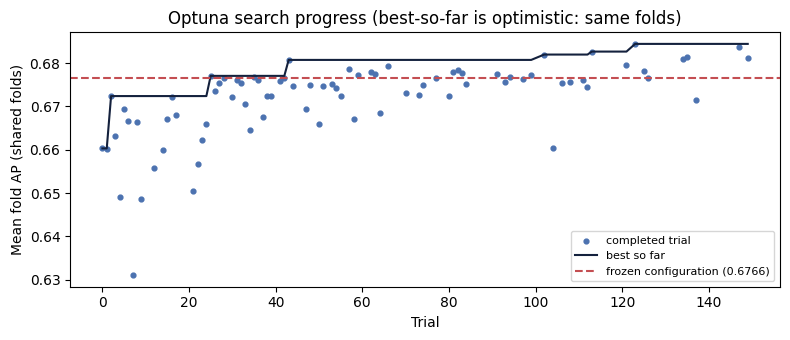

In [4]:
import matplotlib.pyplot as plt

done = trials[trials["state"] == "COMPLETE"].sort_values("number")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(done["number"], done["value"], s=12, color="#4C72B0", label="completed trial")
ax.plot(done["number"], done["value"].cummax(), color="#14213D", label="best so far")
ax.axhline(frozen_aps.mean(), color="#C44E52", ls="--", label=f"frozen configuration ({frozen_aps.mean():.4f})")
ax.set_xlabel("Trial"); ax.set_ylabel("Mean fold AP (shared folds)")
ax.set_title("Optuna search progress (best-so-far is optimistic: same folds)")
ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(RUN_DIR / "search_progress.png", dpi=150); plt.show()

## 4. Nested CV: new procedure vs 06b's procedure

For each shared fold *k*, both procedures see only the other four folds. They tune on three inner stratified folds, refit on all four, and score fold *k*. The outer AP therefore measures each **procedure** — tuning included — on providers it never used to choose anything. Inner searches are smaller (40 Optuna trials; 06b's 20 configurations) to keep compute reasonable.

In [5]:
nested_rows = []
t0 = time.time()
for k in range(N_FOLDS):
    outer_tr, outer_va = np.where(folds != k)[0], np.where(folds == k)[0]
    X_o, y_o = X.iloc[outer_tr].reset_index(drop=True), y[outer_tr]
    inner = np.empty(len(y_o), dtype=int)
    for j, (_, iv) in enumerate(StratifiedKFold(N_INNER, shuffle=True, random_state=SEED + k).split(X_o, y_o)):
        inner[iv] = j

    # New procedure: Optuna + early stopping
    _, p_new = run_search(X_o, y_o, inner, N_TRIALS_NESTED, SEED + k)
    model_new, _ = fit_early_stopped(X_o, y_o, p_new, seed=SEED + 100 + k)
    ap_new = average_precision_score(y[outer_va], model_new.predict_proba(X.iloc[outer_va])[:, 1])

    # 06b procedure: best of the 20 random configurations, fixed tree count
    inner_means = [cv_fixed(c, X_o, y_o, inner)[0].mean() for c in CONFIGS_06B]
    p_old = CONFIGS_06B[int(np.argmax(inner_means))]
    ap_old = average_precision_score(y[outer_va], fixed_pipeline(p_old).fit(X_o, y_o).predict_proba(X.iloc[outer_va])[:, 1])

    nested_rows.append({"outer fold": k, "new procedure AP": ap_new, "06b procedure AP": ap_old,
                        "difference": ap_new - ap_old, "06b config chosen": int(np.argmax(inner_means))})
    print(f"outer fold {k}: new {ap_new:.4f} | 06b {ap_old:.4f}  [{time.time() - t0:.0f}s]")

nested = pd.DataFrame(nested_rows).set_index("outer fold")
nested.to_csv(RUN_DIR / "nested_cv.csv")
summary_nested = nested[["new procedure AP", "06b procedure AP", "difference"]].agg(["mean", "std"])
display(nested)
summary_nested

outer fold 0: new 0.6646 | 06b 0.6768  [129s]


outer fold 1: new 0.6613 | 06b 0.6585  [280s]


outer fold 2: new 0.6703 | 06b 0.6842  [10514s]


outer fold 3: new 0.6438 | 06b 0.6496  [14990s]


outer fold 4: new 0.7101 | 06b 0.7065  [15114s]


,new procedure AP,06b procedure AP,difference,06b config chosen
outer fold,,,,
0,0.6646,0.6768,-0.0123,9
1,0.6613,0.6585,0.0028,9
2,0.6703,0.6842,-0.0139,9
3,0.6438,0.6496,-0.0059,1
4,0.7101,0.7065,0.0036,13


,new procedure AP,06b procedure AP,difference
mean,0.6700,0.6751,-0.0051
std,0.0245,0.0223,0.0082


## 5. Repeated-CV head-to-head on new splits

The Optuna winner was chosen on the shared folds, and the frozen configuration was chosen on them too. Rescoring both on fresh splits (3 × repeated stratified 5-fold, a different seed) removes most of that home advantage. The differences are paired by split.

In [6]:
rows = []
splitter = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED + 1)
for s, (tr, va) in enumerate(splitter.split(X, y)):
    m_new, _ = fit_early_stopped(X.iloc[tr], y[tr], best_params, seed=SEED + 200 + s)
    ap_new = average_precision_score(y[va], m_new.predict_proba(X.iloc[va])[:, 1])
    ap_old = average_precision_score(y[va], fixed_pipeline(FROZEN_PARAMS).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])[:, 1])
    rows.append({"split": s, "Optuna best AP": ap_new, "frozen configuration AP": ap_old, "difference": ap_new - ap_old})
repeated = pd.DataFrame(rows).set_index("split")
repeated.to_csv(RUN_DIR / "repeated_cv.csv")
d = repeated["difference"]
print(f"{len(d)} splits: mean difference {d.mean():+.4f} (SD {d.std(ddof=1):.4f}); Optuna best wins {(d > 0).sum()} of {len(d)}")
repeated.agg(["mean", "std"])

15 splits: mean difference -0.0020 (SD 0.0143); Optuna best wins 5 of 15


,Optuna best AP,frozen configuration AP,difference
mean,0.6766,0.6786,-0.0020
std,0.0264,0.0299,0.0143


## 6. Operating point and development-only refit

The project's threshold rule (highest precision with OOF recall ≥ 80%) applied to the Optuna winner's shared-fold OOF scores, next to the frozen configuration on the same table. The refit uses all training providers with the median tree count across folds and is saved for reference only. It is **not** evaluated on the test set and does not replace the frozen model.

In [7]:
def operating_point(y_true, p, target=0.80):
    prec, rec, thr = precision_recall_curve(y_true, p)
    ok = rec[:-1] >= target
    i = int(np.argmax(np.where(ok, prec[:-1], -1)))
    flagged = p >= thr[i]
    return {"threshold": float(thr[i]), "precision": float(prec[i]), "recall": float(rec[i]),
            "share reviewed": float(flagged.mean()), "pooled OOF AP": float(average_precision_score(y_true, p)),
            "ROC AUC": float(roc_auc_score(y_true, p))}


ops = pd.DataFrame({"Optuna best (early stopping)": operating_point(y, best_oof),
                    "Frozen 06b configuration": operating_point(y, frozen_oof)}).T
display(ops)

final_trees = int(np.median(best_trees))
final_pipeline = fixed_pipeline({**best_params, "n_estimators": final_trees}).fit(X, y)
joblib.dump(final_pipeline, RUN_DIR / "selected_pipeline.joblib")
pd.DataFrame({ID: train[ID], "fold": folds, "y_true": y, "oof_optuna": best_oof, "oof_frozen_config": frozen_oof}) \
    .to_csv(RUN_DIR / "oof_predictions.csv", index=False)

metadata = {
    "run_id": RUN_ID, "quick_run": QUICK_RUN, "development_only": True, "test_set_used": False,
    "feature_variant": "leakfree", "train_path": str(TRAIN_PATH), "feature_order": features,
    "params": best_params, "n_estimators_final": final_trees, "trees_per_fold": best_trees,
    "search": {"sampler": "TPE", "pruner": "median", "n_trials": N_TRIALS, "seed": SEED,
               "early_stopping": {"max_trees": MAX_TREES, "patience": ES_ROUNDS, "inner_fraction": ES_FRACTION,
                                  "metric": "average_precision"}},
    "shared_fold_ap": {"optuna_best_mean": float(best_aps.mean()), "frozen_config_mean": float(frozen_aps.mean())},
    "nested_cv": {"new_mean": float(nested["new procedure AP"].mean()), "old_mean": float(nested["06b procedure AP"].mean()),
                  "diff_mean": float(nested["difference"].mean()), "diff_sd": float(nested["difference"].std(ddof=1)),
                  "trials_per_outer_fold": N_TRIALS_NESTED, "inner_folds": N_INNER},
    "repeated_cv": {"splits": len(repeated), "diff_mean": float(d.mean()), "diff_sd": float(d.std(ddof=1)),
                    "optuna_wins": int((d > 0).sum())},
    "operating_point_80_recall": ops.to_dict(orient="index"),
    "versions": {"lightgbm": lightgbm.__version__, "optuna": optuna.__version__},
}
(RUN_DIR / "selected_metadata.json").write_text(json.dumps(metadata, indent=2, default=float))
print(f"Saved development-only refit ({final_trees} trees) and metadata to {RUN_DIR}")

,threshold,precision,recall,share reviewed,pooled OOF AP,ROC AUC
Optuna best (early stopping),0.1553,0.4626,0.8099,0.1638,0.6769,0.9367
Frozen 06b configuration,0.0867,0.4629,0.8000,0.1617,0.6760,0.9359


Saved development-only refit (148 trees) and metadata to ../artifacts/tuning/20261115_143207_full_leakfree


## Findings

**A wider search with early stopping does not improve on 06b's tuning. Its apparent gain is selection optimism.**

| Check | Optuna + early stopping | 06b procedure / frozen configuration | Difference |
|---|---:|---:|---:|
| Shared folds, best trial (optimistic) | 0.6844 | 0.6766 | +0.0078 |
| **Nested CV, whole procedure (honest)** | **0.6700** | **0.6751** | **−0.0051** (SD 0.0082; new wins 2 of 5) |
| Repeated CV, 15 new splits | 0.6766 | 0.6786 | −0.0020 (SD 0.0143; new wins 5 of 15) |
| Precision at ≥80% OOF recall | 0.463 (16.4% reviewed) | 0.463 (16.2% reviewed) | none |

- **The search looked like a win on the folds it was tuned on.** The best of 81 completed trials beat the frozen configuration by 0.008 mean fold AP. That number is a maximum over many tries on the same five folds.
- **The gain vanishes once tuning is kept away from the scoring folds.** In nested CV the new procedure scores slightly *below* the old one. On 15 fresh splits the chosen configuration loses to the frozen one in 10. Both gaps are well within fold noise.
- **Early stopping chose small, shallow models:** 98–291 trees, `max_depth` 3. The frozen configuration uses 384 trees and 60 leaves, yet both rank providers equally well (pooled OOF AP 0.677 vs 0.676). The loss surface is flat: many quite different models reach the same AP.

**What this means**
- 06b's 20-configuration search was already enough. The frozen LightGBM sits at the practical tuning ceiling for these 26 features, around 0.67–0.68 mean fold AP.
- More tuning is unlikely to help. Further gains would have to come from new information, such as features or a complementary model (for example the LightGBM + logistic regression ensemble), not from searching harder.
- The frozen model, its threshold and its held-out evaluation are unchanged. The refit saved here is development-only and was never scored on the test set.